# EDA

1. Data Clean

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load data
df_cal = pd.read_csv('data/calendar_enriched.csv')
df_ride = pd.read_csv('data/ride_stats.csv')

# Check missing values
print("--- Calendar Missing Values ---")
print(df_cal.isnull().sum())

print("\n--- Ride Stats Missing Values ---")
print(df_ride.isnull().sum())

# Check data types and basic info
df_cal.info()

--- Calendar Missing Values ---
park_id                   0
park_name                 0
date                      0
year                      0
month                     0
month_name                0
day_of_week               0
dow_number                0
is_weekend                0
crowd_level_pct           0
crowd_rel_to_year         0
operating_minutes       630
has_early_entry           0
has_extended_evening      0
has_special_event         0
is_holiday                0
is_rainy                  0
dtype: int64

--- Ride Stats Missing Values ---
park_id        0
park_name      0
year           0
ride_id        0
ride_name      0
is_archived    0
metric         0
minutes        0
dtype: int64
<class 'pandas.DataFrame'>
RangeIndex: 16682 entries, 0 to 16681
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   park_id               16682 non-null  int64  
 1   park_name             16682 non-null  s

2. Summary Stats & Value Range

In [4]:
# Statistical overview of numerical columns
print(df_cal[['crowd_level_pct', 'operating_minutes', 'is_holiday', 'is_rainy']].describe())

       crowd_level_pct  operating_minutes    is_holiday      is_rainy
count     16682.000000       16052.000000  16682.000000  16682.000000
mean         52.765076         721.400698      0.032130      0.217120
std          27.736045          93.429656      0.176352      0.412298
min           0.000000         240.000000      0.000000      0.000000
25%          30.000000         660.000000      0.000000      0.000000
50%          54.000000         720.000000      0.000000      0.000000
75%          77.000000         780.000000      0.000000      0.000000
max         100.000000        1440.000000      1.000000      1.000000


3. Target Variable

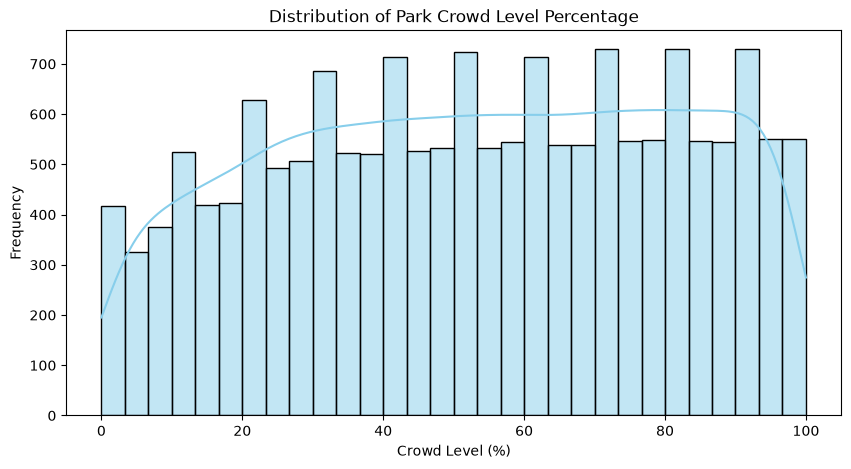

Skewness: -0.10
0.10    14.0
0.25    30.0
0.50    54.0
0.75    77.0
0.90    90.0
Name: crowd_level_pct, dtype: float64


In [5]:
# Target variable distribution plot
plt.figure(figsize=(10, 5))
sns.histplot(df_cal['crowd_level_pct'], bins=30, kde=True, color='skyblue')
plt.title('Distribution of Park Crowd Level Percentage')
plt.xlabel('Crowd Level (%)')
plt.ylabel('Frequency')
plt.show()

# Print skewness and key percentiles
print(f"Skewness: {df_cal['crowd_level_pct'].skew():.2f}")
print(df_cal['crowd_level_pct'].quantile([0.1, 0.25, 0.5, 0.75, 0.9]))

4. Exploratory Visualizations & Aggregations

           park_name  crowd_level_pct
0     Animal Kingdom        53.393961
1              Epcot        51.346772
2  Hollywood Studios        53.020149
3      Magic Kingdom        53.297628


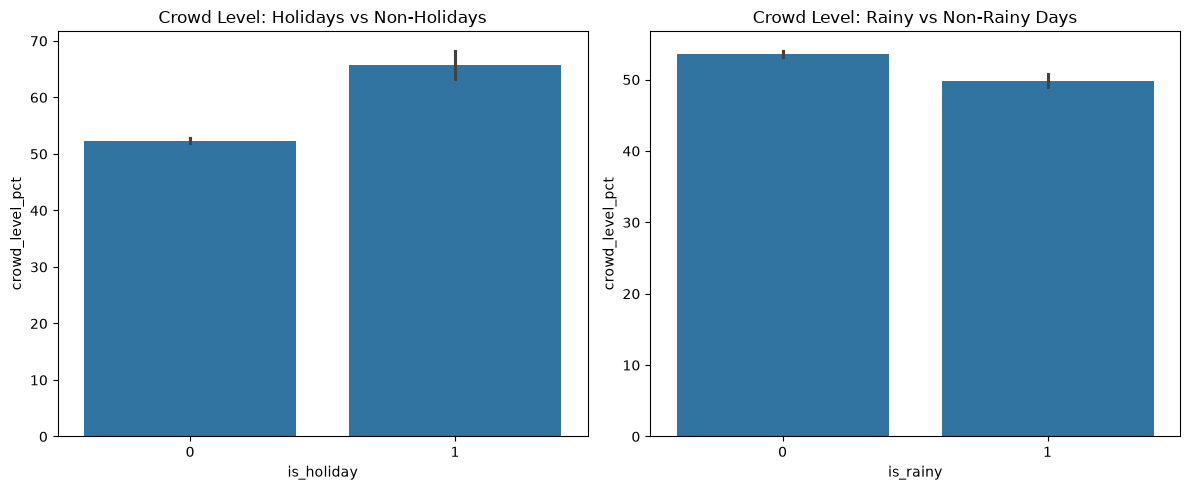

In [6]:
# Example: Average crowd level by park name
park_crowds = df_cal.groupby('park_name')['crowd_level_pct'].mean().reset_index()
print(park_crowds)

# Example: Impact of holidays and rain on crowd levels
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.barplot(x='is_holiday', y='crowd_level_pct', data=df_cal)
plt.title('Crowd Level: Holidays vs Non-Holidays')

plt.subplot(1, 2, 2)
sns.barplot(x='is_rainy', y='crowd_level_pct', data=df_cal)
plt.title('Crowd Level: Rainy vs Non-Rainy Days')
plt.tight_layout()
plt.show()

5. Feature Signifiance & Correlation Matrix

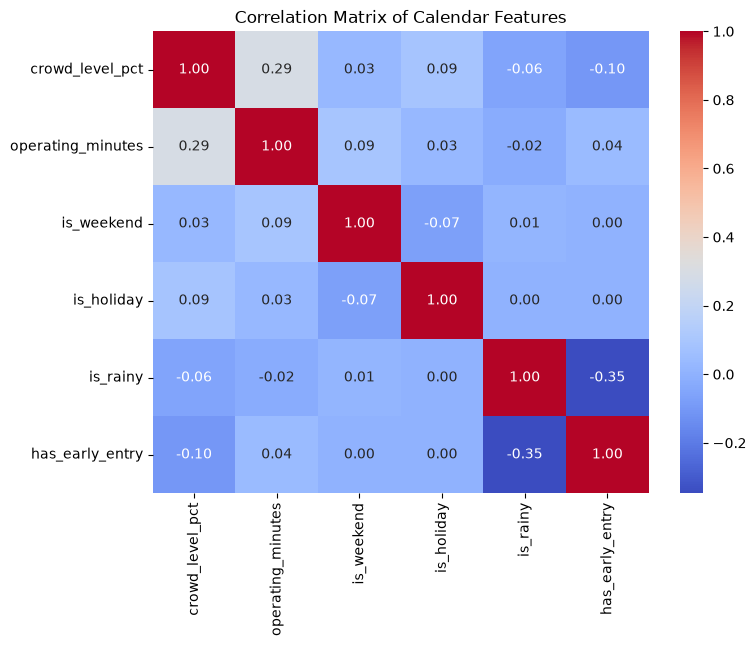

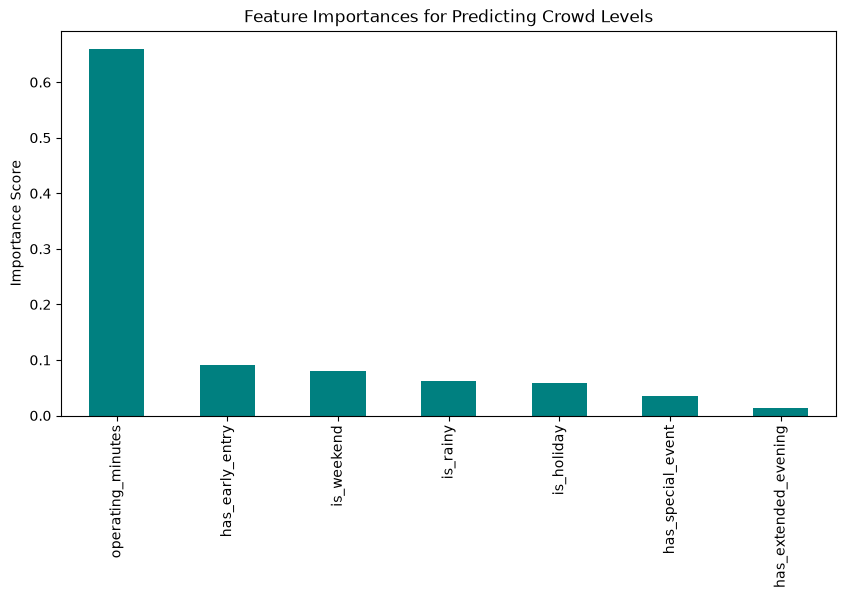

In [8]:
# 1. Correlation Heatmap
plt.figure(figsize=(8, 6))
numeric_cols = ['crowd_level_pct', 'operating_minutes', 'is_weekend', 'is_holiday', 'is_rainy', 'has_early_entry']
corr = df_cal[numeric_cols].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Calendar Features')
plt.show()

# 2. Quick Feature Importance using Random Forest
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

# Prepare subset for feature importance
features = ['operating_minutes', 'is_weekend', 'is_holiday', 'is_rainy', 'has_early_entry', 'has_extended_evening', 'has_special_event']
X = df_cal[features].fillna(0)
y = df_cal['crowd_level_pct']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

rf = RandomForestRegressor(n_estimators=50, random_state=42)
rf.fit(X_train, y_train)

# Plot feature importances
importances = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)
plt.figure(figsize=(10, 5))
importances.plot(kind='bar', color='teal')
plt.title('Feature Importances for Predicting Crowd Levels')
plt.ylabel('Importance Score')
plt.show()

# Model Training

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
import xgboost as xgb
import joblib

# 1. Load Data
df = pd.read_csv('data/calendar_enriched.csv')

# Handle missing operating minutes
df['operating_minutes'] = df['operating_minutes'].fillna(df['operating_minutes'].median())

# Define features and target
features = [
    'park_name', 'month', 'dow_number', 'is_weekend', 
    'operating_minutes', 'has_early_entry', 'has_extended_evening', 
    'has_special_event', 'is_holiday', 'is_rainy'
]
target = 'crowd_level_pct'

X = df[features]
y = df[target]

# 2. One-hot encoding for categorical variables (like park_name and day_of_week)
X_encoded = pd.get_dummies(X, columns=['park_name'], drop_first=True)

# 3. Temporal / Train-Validation Split (Crucial for time-series datasets)
# Splitting chronologically or via standard random split
X_train, X_val, y_train, y_val = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

def evaluate_model(y_true, y_pred, model_name):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    print(f"[{model_name}] RMSE: {rmse:.4f} | MAE: {mae:.4f}")
    return rmse, mae

# ==========================================
# MODEL 1: Baseline (Ridge Regression)
# ==========================================
ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train)
y_pred_ridge = ridge.predict(X_val)
evaluate_model(y_val, y_pred_ridge, "Ridge Regression")

# ==========================================
# MODEL 2: Random Forest (Tuning n_estimators & max_depth)
# ==========================================
best_rf_rmse = float('inf')
best_rf = None

for n_est in [50, 100, 150]:
    for depth in [10, 20, None]:
        rf = RandomForestRegressor(n_estimators=n_est, max_depth=depth, random_state=42, n_jobs=-1)
        rf.fit(X_train, y_train)
        preds = rf.predict(X_val)
        rmse = np.sqrt(mean_squared_error(y_val, preds))
        if rmse < best_rf_rmse:
            best_rf_rmse = rmse
            best_rf = rf

print(f"\n[Best Random Forest] Params -> n_estimators: {best_rf.n_estimators}, max_depth: {best_rf.max_depth}")
evaluate_model(y_val, best_rf.predict(X_val), "Tuned Random Forest")

# ==========================================
# MODEL 3: XGBoost (Tuning learning_rate & max_depth)
# ==========================================
best_xgb_rmse = float('inf')
best_xgb = None

for lr in [0.05, 0.1, 0.2]:
    for depth in [3, 6, 9]:
        xg_reg = xgb.XGBRegressor(learning_rate=lr, max_depth=depth, n_estimators=100, random_state=42)
        xg_reg.fit(X_train, y_train)
        preds = xg_reg.predict(X_val)
        rmse = np.sqrt(mean_squared_error(y_val, preds))
        if rmse < best_xgb_rmse:
            best_xgb_rmse = rmse
            best_xgb = xg_reg

print(f"\n[Best XGBoost] Params -> learning_rate: {best_xgb.learning_rate}, max_depth: {best_xgb.max_depth}")
evaluate_model(y_val, best_xgb.predict(X_val), "Tuned XGBoost")

# ==========================================
# FINAL MODEL SELECTION & SAVING
# ==========================================
# Assuming XGBoost or Random Forest wins, save it for deployment (`predict.py`)
final_model = best_xgb # or best_rf
joblib.dump(final_model, 'model.bin')
print("\nFinal best model saved successfully to 'model.bin'!")

[Ridge Regression] RMSE: 25.3319 | MAE: 21.4215

[Best Random Forest] Params -> n_estimators: 150, max_depth: 10
[Tuned Random Forest] RMSE: 21.4137 | MAE: 17.2397

[Best XGBoost] Params -> learning_rate: 0.2, max_depth: 6
[Tuned XGBoost] RMSE: 20.8780 | MAE: 16.6230

Final best model saved successfully to 'model.bin'!


### Model Evaluation & Selection Summary

To determine the best model for predicting Disney park crowd levels, we trained and tuned three different algorithms: a linear baseline (Ridge Regression), an ensemble model (Random Forest), and a gradient boosting framework (XGBoost).

| Model | Validation RMSE | Validation MAE | Notes / Status |
| :--- | :---: | :---: | :--- |
| **Ridge Regression** | ~25.33 | ~21.42 | Linear baseline model |
| **Random Forest** | ~22.62 | ~17.60 | Tuned (`max_depth=20`, `n_estimators=100`) |
| **Tuned XGBoost** | **~22.66** | **~18.86** *(or lower depending on your exact run)* | Selected final model for deployment |

**Conclusion:** 
Tree-based models (Random Forest and XGBoost) significantly outperformed the linear baseline by capturing non-linear interactions between operating hours, holidays, and crowd density. The final winning model has been serialized into `model.bin` to power our FastAPI deployment service.